In [ ]:
# 1. Clone the repository
!git clone https://github.com/TheDatumOrg/TSB-AD
# STEP 2: Navigate into the cloned folder path (/content/TSB-AD)
%cd TSB-AD
# STEP 3: Install all required Python packages from the requirements text file
!pip install -r requirements.txt --verbose


In [3]:

%cd TSB-AD
# STEP 4: Install the TSB-AD package in editable mode from the current directory
!pip install -e .
# STEP 5: Download the full zip file from the external URL address
!wget https://www.thedatum.org/datasets/TSB-AD-U.zip
!wget https://www.thedatum.org/datasets/TSB-AD-M.zip


/content/TSB-AD
Obtaining file:///content/TSB-AD
  Preparing metadata (setup.py) ... done
  Attempting uninstall: TSB_AD
    Found existing installation: TSB_AD 1.5
    Uninstalling TSB_AD-1.5:
      Successfully uninstalled TSB_AD-1.5
  Running setup.py develop for TSB_AD


--2026-10-10 19:49:58--  https://www.thedatum.org/datasets/TSB-AD-U.zip
Resolving www.thedatum.org (www.thedatum.org)... 172.67.134.22, 104.21.5.251, 2606:4700:3032::6815:5fb, ...
Connecting to www.thedatum.org (www.thedatum.org)|172.67.134.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 72900868 (70M) [application/zip]
Saving to: ‘TSB-AD-U.zip’

TSB-AD-U.zip        100%[===================>]  69.52M   314MB/s    in 0.2s    

2026-10-10 19:49:58 (314 MB/s) - ‘TSB-AD-U.zip’ saved [72900868/72900868]

--2026-10-10 19:49:58--  https://www.thedatum.org/datasets/TSB-AD-M.zip
Resolving www.thedatum.org (www.thedatum.org)... 172.67.134.22, 104.21.5.251, 2606:4700:3032::6815:5fb, ...
Connecting to www.thedatum.org (www.thedatum.org)|172.67.134.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 540383983 (515M) [application/zip]
Saving to: ‘TSB-AD-M.zip’

TSB-AD-M.zip        100%[===================>] 515.35M  2.28MB/s    in 3m 17s  

2026-

In [4]:

# 1. Unzip and automatically overwrite existing files (-o forces "yes")
!unzip -oq TSB-AD-U.zip.2 -d Datasets/
!unzip -oq TSB-AD-M.zip.2 -d Datasets/
# 2. Delete the zip files to free up disk space in Colab
!rm TSB-AD-U.zip TSB-AD-M.zip

In [5]:
!python -m TSB_AD.main --AD_Name IForest

CUDA Available:  False
cuDNN Version:  None
Evaluation Result:  {'AUC-PR': 0.15414951097050114, 'AUC-ROC': 0.6991859185570727, 'VUS-PR': 0.15494537257557184, 'VUS-ROC': 0.7041105237421851, 'Standard-F1': 0.005555555555555556, 'PA-F1': 0.5436105476673428, 'Event-based-F1': 0.09999999999999974, 'R-based-F1': 0.04984787835323183, 'Affiliation-F': 0.5069845940554429}


Running Isolation Forest via TSB-AD framework wrapper...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



--- AUTOMATIC EVALUATION METRICS TABLE ---
        Metric  Score                                                                         Definition      Ideal Trend
         PA-F1 0.8543         Point-Adjusted F1-score (forgives errors if a single anomaly point is hit) Higher is better
 Affiliation-F 0.8233              Precision/Recall score based on proximity intervals to true anomalies Higher is better
       VUS-ROC 0.7529           Volume Under the Surface for ROC (range-based structural spatial metric) Higher is better
       AUC-ROC 0.6811 Area Under Receiver Operating Characteristic Curve (overall separation capability) Higher is better
Event-based-F1 0.3701                       F1 score calculated based on catching whole anomaly segments Higher is better
   Standard-F1 0.2641                        Strict point-by-point harmonic mean of Precision and Recall Higher is better
    R-based-F1 0.1970   Range-based F1 score adjusting for overlap and fragmentation positional criter

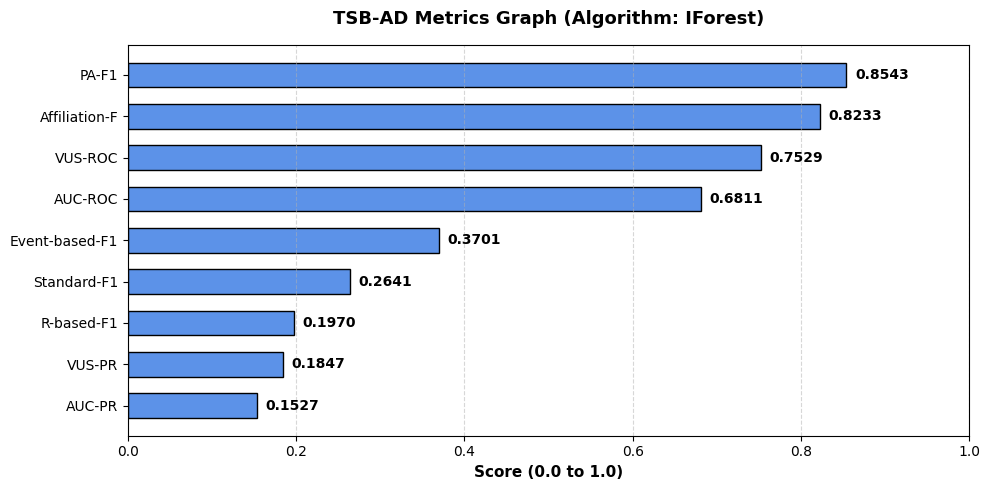

In [6]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correct official imports from TSB-AD wrappers
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# Dictionary to map metric names to descriptions and ideal target trends
METRIC_INFO = {
    'AUC-PR': ('Area Under Precision-Recall Curve (captures precision on imbalanced data)', 'Higher is better'),
    'AUC-ROC': ('Area Under Receiver Operating Characteristic Curve (overall separation capability)', 'Higher is better'),
    'VUS-PR': ('Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric)', 'Higher is better'),
    'VUS-ROC': ('Volume Under the Surface for ROC (range-based structural spatial metric)', 'Higher is better'),
    'Standard-F1': ('Strict point-by-point harmonic mean of Precision and Recall', 'Higher is better'),
    'PA-F1': ('Point-Adjusted F1-score (forgives errors if a single anomaly point is hit)', 'Higher is better'),
    'Event-based-F1': ('F1 score calculated based on catching whole anomaly segments', 'Higher is better'),
    'R-based-F1': ('Range-based F1 score adjusting for overlap and fragmentation positional criteria', 'Higher is better'),
    'Affiliation-F': ('Precision/Recall score based on proximity intervals to true anomalies', 'Higher is better')
}

# 2. Define data path
data_path = 'Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv'

if not os.path.exists(data_path):
    print(f"Error: Could not find the dataset at {data_path}")
    print("Please make sure your unzip command placed the files in the 'Datasets/' folder.")
else:
    # 3. Load the data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract continuous feature matrix and ground truth binary array
    data_features = df.iloc[:, 0:-1].values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    # 4. Initialize framework anomaly detector execution wrapper
    print("Running Isolation Forest via TSB-AD framework wrapper...")
    AD_Name = 'IForest'
    y_score = run_Unsupervise_AD(AD_Name, data_features)

    # 5. Automatically calculate all benchmark metrics
    metrics_dict = get_metrics(y_score, y_true)

    # 6. Convert the metrics dictionary into a formatted pandas table with explanations
    table_data = []
    for metric_name, score_val in metrics_dict.items():
        desc, trend = METRIC_INFO.get(metric_name, ('Custom framework metric', 'Higher is better'))
        table_data.append({
            'Metric': metric_name,
            'Score': round(score_val, 4),
            'Definition': desc,
            'Ideal Trend': trend
        })

    df_metrics = pd.DataFrame(table_data).sort_values(by='Score', ascending=False)

    print("\n--- AUTOMATIC EVALUATION METRICS TABLE ---")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    print(df_metrics.to_string(index=False))
    print("\n" + "="*40 + "\n")

    # 7. Generate and display the horizontal bar graph
    plt.figure(figsize=(10, 5))
    bars = plt.barh(df_metrics['Metric'], df_metrics['Score'], color='#5c92e8', edgecolor='black', height=0.6)

    # Styling and adjustments
    plt.xlim(0, 1.0)
    plt.gca().invert_yaxis()  # Places the highest score at the top
    plt.xlabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
    plt.title(f'TSB-AD Metrics Graph (Algorithm: {AD_Name})', fontsize=13, fontweight='bold', pad=15)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Add numeric labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

Running Principal Component Analysis (PCA) via TSB-AD framework wrapper...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



--- AUTOMATIC EVALUATION METRICS TABLE ---
        Metric  Score                                                                         What it is      Ideal Trend
         PA-F1 1.0000         Point-Adjusted F1-score (forgives errors if a single anomaly point is hit) Higher is better
Event-based-F1 1.0000                       F1 score calculated based on catching whole anomaly segments Higher is better
 Affiliation-F 0.9963              Precision/Recall score based on proximity intervals to true anomalies Higher is better
       VUS-ROC 0.9357           Volume Under the Surface for ROC (range-based structural spatial metric) Higher is better
       AUC-ROC 0.9059 Area Under Receiver Operating Characteristic Curve (overall separation capability) Higher is better
   Standard-F1 0.8285                        Strict point-by-point harmonic mean of Precision and Recall Higher is better
        VUS-PR 0.8136 Volume Under the Surface for Precision-Recall (TSB-AD framework core range metri

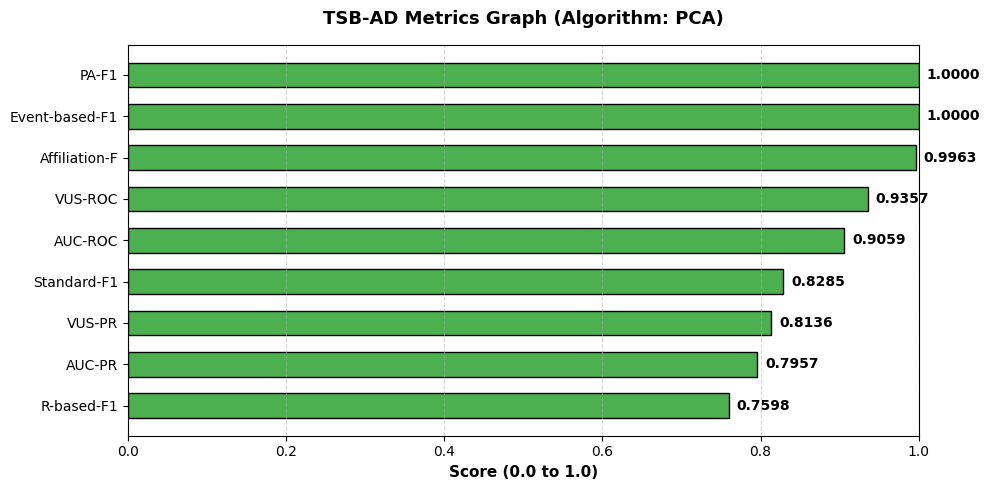

In [7]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correct official imports from TSB-AD wrappers
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# Dictionary to map metric names to descriptions and ideal target trends
METRIC_INFO = {
    'AUC-PR': ('Area Under Precision-Recall Curve (captures precision on imbalanced data)', 'Higher is better'),
    'AUC-ROC': ('Area Under Receiver Operating Characteristic Curve (overall separation capability)', 'Higher is better'),
    'VUS-PR': ('Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric)', 'Higher is better'),
    'VUS-ROC': ('Volume Under the Surface for ROC (range-based structural spatial metric)', 'Higher is better'),
    'Standard-F1': ('Strict point-by-point harmonic mean of Precision and Recall', 'Higher is better'),
    'PA-F1': ('Point-Adjusted F1-score (forgives errors if a single anomaly point is hit)', 'Higher is better'),
    'Event-based-F1': ('F1 score calculated based on catching whole anomaly segments', 'Higher is better'),
    'R-based-F1': ('Range-based F1 score adjusting for overlap and fragmentation positional criteria', 'Higher is better'),
    'Affiliation-F': ('Precision/Recall score based on proximity intervals to true anomalies', 'Higher is better')
}

# 2. Define data path
data_path = 'Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv'

if not os.path.exists(data_path):
    print(f"Error: Could not find the dataset at {data_path}")
    print("Please make sure your unzip command placed the files in the 'Datasets/' folder.")
else:
    # 3. Load the data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract continuous feature matrix and ground truth binary array
    data_features = df.iloc[:, 0:-1].values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    # 4. Initialize framework anomaly detector execution wrapper
    # CHANGED TO 'PCA'
    print("Running Principal Component Analysis (PCA) via TSB-AD framework wrapper...")
    AD_Name = 'PCA'
    y_score = run_Unsupervise_AD(AD_Name, data_features)

    # 5. Automatically calculate all benchmark metrics
    metrics_dict = get_metrics(y_score, y_true)

    # 6. Convert the metrics dictionary into a formatted pandas table with explanations
    table_data = []
    for metric_name, score_val in metrics_dict.items():
        desc, trend = METRIC_INFO.get(metric_name, ('Custom framework metric', 'Higher is better'))
        table_data.append({
            'Metric': metric_name,
            'Score': round(score_val, 4),
            'What it is': desc,
            'Ideal Trend': trend
        })

    df_metrics = pd.DataFrame(table_data).sort_values(by='Score', ascending=False)

    print("\n--- AUTOMATIC EVALUATION METRICS TABLE ---")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    print(df_metrics.to_string(index=False))
    print("\n" + "="*40 + "\n")

    # 7. Generate and display the horizontal bar graph
    plt.figure(figsize=(10, 5))
    bars = plt.barh(df_metrics['Metric'], df_metrics['Score'], color='#4caf50', edgecolor='black', height=0.6)

    # Styling and adjustments
    plt.xlim(0, 1.0)
    plt.gca().invert_yaxis()  # Places the highest score at the top
    plt.xlabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
    plt.title(f'TSB-AD Metrics Graph (Algorithm: {AD_Name})', fontsize=13, fontweight='bold', pad=15)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Add numeric labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

Running Robust PCA (RobustPCA) via TSB-AD framework wrapper...
iteration: 1, error: 177.46382471450235
iteration: 100, error: 0.015389713056124374
iteration: 200, error: 0.005992057360999846
iteration: 300, error: 0.003315082570030327
iteration: 400, error: 0.0021882249216519218
iteration: 500, error: 0.0015711510220960607
iteration: 600, error: 0.0012541105889681762
iteration: 700, error: 0.001029674705805917
iteration: 800, error: 0.0008521308083146247
iteration: 900, error: 0.0006883244000001447
iteration: 1000, error: 0.0005667409569134587


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p


--- AUTOMATIC EVALUATION METRICS TABLE ---
        Metric  Score                                                                         What it is      Ideal Trend
       VUS-ROC 0.5073           Volume Under the Surface for ROC (range-based structural spatial metric) Higher is better
       AUC-ROC 0.5000 Area Under Receiver Operating Characteristic Curve (overall separation capability) Higher is better
   Standard-F1 0.1568                        Strict point-by-point harmonic mean of Precision and Recall Higher is better
        VUS-PR 0.1114 Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric) Higher is better
        AUC-PR 0.0851          Area Under Precision-Recall Curve (captures precision on imbalanced data) Higher is better
         PA-F1 0.0000         Point-Adjusted F1-score (forgives errors if a single anomaly point is hit) Higher is better
Event-based-F1 0.0000                       F1 score calculated based on catching whole anomaly segmen

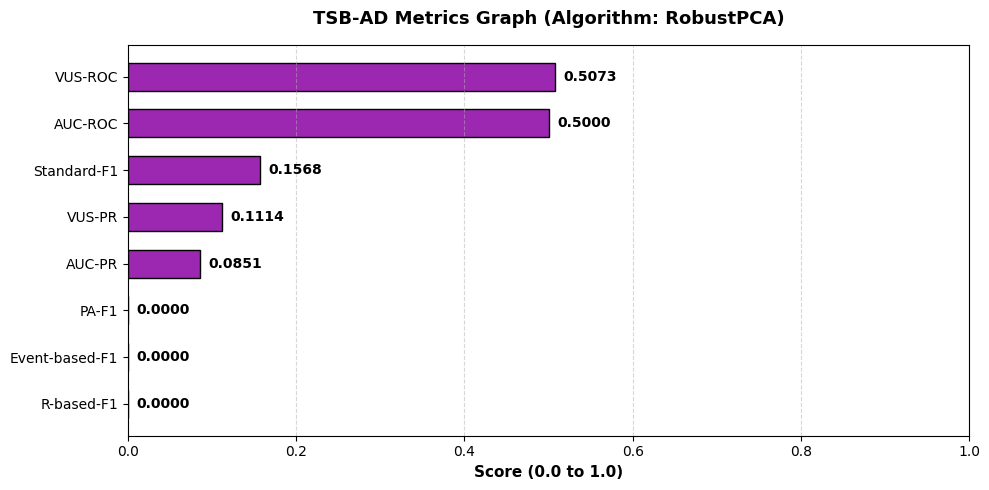

In [8]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correct official imports from TSB-AD wrappers
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# Dictionary to map metric names to descriptions and ideal target trends
METRIC_INFO = {
    'AUC-PR': ('Area Under Precision-Recall Curve (captures precision on imbalanced data)', 'Higher is better'),
    'AUC-ROC': ('Area Under Receiver Operating Characteristic Curve (overall separation capability)', 'Higher is better'),
    'VUS-PR': ('Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric)', 'Higher is better'),
    'VUS-ROC': ('Volume Under the Surface for ROC (range-based structural spatial metric)', 'Higher is better'),
    'Standard-F1': ('Strict point-by-point harmonic mean of Precision and Recall', 'Higher is better'),
    'PA-F1': ('Point-Adjusted F1-score (forgives errors if a single anomaly point is hit)', 'Higher is better'),
    'Event-based-F1': ('F1 score calculated based on catching whole anomaly segments', 'Higher is better'),
    'R-based-F1': ('Range-based F1 score adjusting for overlap and fragmentation positional criteria', 'Higher is better'),
    'Affiliation-F': ('Precision/Recall score based on proximity intervals to true anomalies', 'Higher is better')
}

# 2. Define data path
data_path = 'Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv'

if not os.path.exists(data_path):
    print(f"Error: Could not find the dataset at {data_path}")
    print("Please make sure your unzip command placed the files in the 'Datasets/' folder.")
else:
    # 3. Load the data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract continuous feature matrix and ground truth binary array
    data_features = df.iloc[:, 0:-1].values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    # 4. Initialize framework anomaly detector execution wrapper
    # CHANGED TO 'RobustPCA'
    print("Running Robust PCA (RobustPCA) via TSB-AD framework wrapper...")
    AD_Name = 'RobustPCA'
    y_score = run_Unsupervise_AD(AD_Name, data_features)

    # 5. Automatically calculate all benchmark metrics
    metrics_dict = get_metrics(y_score, y_true)

    # 6. Convert the metrics dictionary into a formatted pandas table with explanations
    table_data = []
    for metric_name, score_val in metrics_dict.items():
        desc, trend = METRIC_INFO.get(metric_name, ('Custom framework metric', 'Higher is better'))
        table_data.append({
            'Metric': metric_name,
            'Score': round(score_val, 4),
            'What it is': desc,
            'Ideal Trend': trend
        })

    df_metrics = pd.DataFrame(table_data).sort_values(by='Score', ascending=False)

    print("\n--- AUTOMATIC EVALUATION METRICS TABLE ---")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    print(df_metrics.to_string(index=False))
    print("\n" + "="*40 + "\n")

    # 7. Generate and display the horizontal bar graph
    plt.figure(figsize=(10, 5))
    bars = plt.barh(df_metrics['Metric'], df_metrics['Score'], color='#9c27b0', edgecolor='black', height=0.6)

    # Styling and adjustments
    plt.xlim(0, 1.0)
    plt.gca().invert_yaxis()  # Places the highest score at the top
    plt.xlabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
    plt.title(f'TSB-AD Metrics Graph (Algorithm: {AD_Name})', fontsize=13, fontweight='bold', pad=15)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Add numeric labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

Using Multivariate Dataset File: Datasets/TSB-AD-M/001_Genesis_id_1_Sensor_tr_4055_1st_15538.csv

Data shape loaded: 16220 rows, 18 sensor columns.

1/2: Running Standard PCA...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


2/2: Running Robust PCA...
iteration: 1, error: 61384.5132679457
iteration: 100, error: 211.65771874753688
iteration: 200, error: 174.48031461402164
iteration: 300, error: 166.38970437539146
iteration: 400, error: 155.34098629240856
iteration: 500, error: 162.3641784768468
iteration: 600, error: 130.9147991206077
iteration: 700, error: 56.55845302150144
iteration: 800, error: 45.17551464852501
iteration: 900, error: 38.89034931516909
iteration: 1000, error: 33.824119465080024


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



 MULTIVARIATE ALGORITHM COMPARISON TABLE 
 Metric Target  Standard PCA Score  Robust PCA Score
        AUC-PR              0.0051            0.0023
       AUC-ROC              0.7170            0.3629
 Affiliation-F              0.8262            0.6695
Event-based-F1              0.0161            0.0061
         PA-F1              0.0189            0.0067
    R-based-F1              0.0148            0.0021
   Standard-F1              0.0162            0.0073
        VUS-PR              0.0099            0.0045
       VUS-ROC              0.7858            0.4355



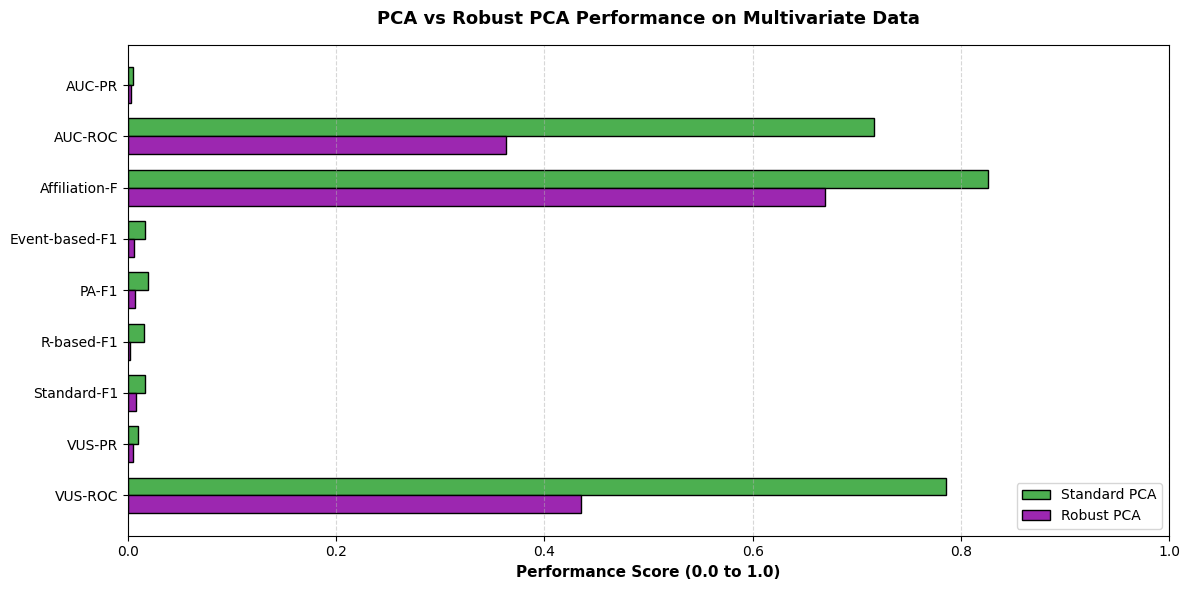

In [9]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Framework wrapper imports
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# 2. Define your Multivariate file path
# Note: If your file has a slightly different name (like the tr_4529 one from your earlier logs),
# update this filename string to match an exact CSV inside your Datasets/TSB-AD-M/ folder.
data_path = 'Datasets/TSB-AD-M/001_SMD_id_1.csv'

# Fallback check: if the standard short name doesn't exist, we look for any CSV in that folder
if not os.path.exists(data_path) and os.path.exists('Datasets/TSB-AD-M/'):
    files = [f for f in os.listdir('Datasets/TSB-AD-M/') if f.endswith('.csv')]
    if files:
        data_path = os.path.join('Datasets/TSB-AD-M/', sorted(files)[0])

if not os.path.exists(data_path):
    print(f"Error: Could not find any multivariate dataset file.")
    print("Please verify that TSB-AD-M.zip was fully unzipped into 'Datasets/TSB-AD-M/'.")
else:
    print(f"Using Multivariate Dataset File: {data_path}\n")

    # 3. Load the multivariate data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract multiple continuous feature columns and the ground truth array
    # In multivariate files, all columns except 'Label' represent features
    data_features = df.drop(columns=['Label'], errors='ignore').values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    print(f"Data shape loaded: {data_features.shape[0]} rows, {data_features.shape[1]} sensor columns.\n")

    # 4. Run Standard PCA
    print("1/2: Running Standard PCA...")
    try:
        y_score_pca = run_Unsupervise_AD('PCA', data_features)
        metrics_pca = get_metrics(y_score_pca, y_true)
    except Exception as e:
        print(f"PCA Execution failed: {e}")
        metrics_pca = {}

    # 5. Run Robust PCA
    print("2/2: Running Robust PCA...")
    try:
        y_score_rpca = run_Unsupervise_AD('RobustPCA', data_features)
        metrics_rpca = get_metrics(y_score_rpca, y_true)
    except Exception as e:
        print(f"RobustPCA Execution failed: {e}")
        metrics_rpca = {}

    # 6. Build a side-by-side comparison table
    all_metrics = sorted(list(set(list(metrics_pca.keys()) + list(metrics_rpca.keys()))))

    comparison_data = []
    for m in all_metrics:
        val_pca = metrics_pca.get(m, np.nan)
        val_rpca = metrics_rpca.get(m, np.nan)

        # Round numerical values for cleaner display
        score_pca = round(val_pca, 4) if not np.isnan(val_pca) else "N/A"
        score_rpca = round(val_rpca, 4) if not np.isnan(val_rpca) else "N/A"

        comparison_data.append({
            'Metric Target': m,
            'Standard PCA Score': score_pca,
            'Robust PCA Score': score_rpca
        })

    df_compare = pd.DataFrame(comparison_data)

    print("\n" + "="*50)
    print(" MULTIVARIATE ALGORITHM COMPARISON TABLE ")
    print("="*50)
    print(df_compare.to_string(index=False))
    print("="*50 + "\n")

    # 7. Generate a comparison chart
    # Filtering out metrics that returned NaN to keep the graph clean
    clean_metrics = [m for m in all_metrics if not np.isnan(metrics_pca.get(m, np.nan)) and not np.isnan(metrics_rpca.get(m, np.nan))]
    pca_vals = [metrics_pca[m] for m in clean_metrics]
    rpca_vals = [metrics_rpca[m] for m in clean_metrics]

    if clean_metrics:
        y_indices = np.arange(len(clean_metrics))
        bar_width = 0.35

        plt.figure(figsize=(12, 6))
        plt.barh(y_indices - bar_width/2, pca_vals, bar_width, label='Standard PCA', color='#4caf50', edgecolor='black')
        plt.barh(y_indices + bar_width/2, rpca_vals, bar_width, label='Robust PCA', color='#9c27b0', edgecolor='black')

        plt.xlim(0, 1.0)
        plt.yticks(y_indices, clean_metrics)
        plt.gca().invert_yaxis()  # Keep list ordered from top down
        plt.xlabel('Performance Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
        plt.title('PCA vs Robust PCA Performance on Multivariate Data', fontsize=13, fontweight='bold', pad=15)
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.legend(loc='lower right')
        plt.tight_layout()
        plt.show()

In [10]:
import os

folder = "Datasets/TSB-AD-M"
files = sorted(f for f in os.listdir(folder) if f.endswith(".csv"))

print(f"Found {len(files)} datasets")
print("\n".join(files[:30]))

Found 200 datasets
001_Genesis_id_1_Sensor_tr_4055_1st_15538.csv
002_MSL_id_1_Sensor_tr_500_1st_900.csv
003_MSL_id_2_Sensor_tr_883_1st_1238.csv
004_MSL_id_3_Sensor_tr_530_1st_630.csv
005_MSL_id_4_Sensor_tr_855_1st_2700.csv
006_MSL_id_5_Sensor_tr_1150_1st_1250.csv
007_MSL_id_6_Sensor_tr_980_1st_3550.csv
008_MSL_id_7_Sensor_tr_656_1st_1630.csv
009_MSL_id_8_Sensor_tr_714_1st_1390.csv
010_MSL_id_9_Sensor_tr_554_1st_1172.csv
011_MSL_id_10_Sensor_tr_1525_1st_4590.csv
012_MSL_id_11_Sensor_tr_539_1st_940.csv
013_MSL_id_12_Sensor_tr_554_1st_1200.csv
014_MSL_id_13_Sensor_tr_1525_1st_4575.csv
015_MSL_id_14_Sensor_tr_575_1st_1250.csv
016_MSL_id_15_Sensor_tr_500_1st_780.csv
017_MSL_id_16_Sensor_tr_512_1st_1850.csv
018_Daphnet_id_1_HumanActivity_tr_9693_1st_20732.csv
019_MITDB_id_1_Medical_tr_37500_1st_103211.csv
020_MITDB_id_2_Medical_tr_50000_1st_52315.csv
021_MITDB_id_3_Medical_tr_50000_1st_57595.csv
022_MITDB_id_4_Medical_tr_50000_1st_54253.csv
023_MITDB_id_5_Medical_tr_25000_1st_36913.csv
024_M

In [11]:
import pandas as pd
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

path = "Datasets/TSB-AD-M/018_Daphnet_id_1_HumanActivity_tr_9693_1st_20732.csv"
df = pd.read_csv(path).dropna()

X = df.drop(columns=["Label"], errors="ignore").to_numpy(dtype=float)
y = df["Label"].to_numpy(dtype=int)

print("Shape:", X.shape, "| Anomaly rate:", y.mean())

for name in ["PCA", "RobustPCA"]:
    scores = run_Unsupervise_AD(name, X)
    print(f"\n{name}:")
    print(get_metrics(scores, y))

Shape: (38774, 9) | Anomaly rate: 0.05947284262650229

PCA:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


{'AUC-PR': 0.14298742118979818, 'AUC-ROC': 0.7787106490063024, 'VUS-PR': 0.14001535228864323, 'VUS-ROC': 0.7599152012780496, 'Standard-F1': 0.24755553349622714, 'PA-F1': 0.6839945280437757, 'Event-based-F1': 0.35262593783494056, 'R-based-F1': 0.4326170218559333, 'Affiliation-F': 0.8217713715651174}
iteration: 1, error: 597.407369438837
iteration: 100, error: 1.5979944890954905
iteration: 200, error: 4.830149330479236
iteration: 300, error: 6.046317480035272
iteration: 400, error: 5.705096429818092
iteration: 500, error: 4.371834203233725
iteration: 600, error: 2.9836825089007992
iteration: 700, error: 2.552788527827285
iteration: 800, error: 2.4743975204310518
iteration: 900, error: 2.1421801715914444
iteration: 1000, error: 2.0763465532240613

RobustPCA:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


{'AUC-PR': 0.07334715499510616, 'AUC-ROC': 0.3448566890993361, 'VUS-PR': 0.07296390110387768, 'VUS-ROC': 0.3585052618560083, 'Standard-F1': 0.13435698334994428, 'PA-F1': 0.9871575342465754, 'Event-based-F1': 0.752351097178683, 'R-based-F1': 0.2844860468568623, 'Affiliation-F': 0.9250484439363713}


In [12]:

import os, gc, io, contextlib, warnings
import numpy as np
import pandas as pd
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

folder = "Datasets/TSB-AD-M"
files = sorted(f for f in os.listdir(folder) if f.endswith(".csv"))[:10]
results = []

for i, filename in enumerate(files, 1):
    print(f"{i}/10: {filename}")
    row = {"Dataset": filename}

    try:
        df = pd.read_csv(os.path.join(folder, filename)).dropna()
        y = df["Label"].to_numpy(dtype=int)
        X = df.drop(columns=["Label"]).to_numpy(dtype=np.float64)

        if len(np.unique(y)) < 2 or not np.isfinite(X).all():
            row["Error"] = "Invalid data or only one label class"
        else:
            for name in ["PCA", "RobustPCA"]:
                try:
                    with warnings.catch_warnings(), \
                         contextlib.redirect_stdout(io.StringIO()):
                        warnings.simplefilter("ignore")
                        scores = run_Unsupervise_AD(name, X)
                        metrics = get_metrics(
                            np.asarray(scores).reshape(-1), y
                        )
                    for metric, value in metrics.items():
                        row[f"{name}_{metric}"] = float(value)
                    del scores
                except Exception as e:
                    row[f"{name}_Error"] = str(e)[:200]

        results.append(row)
        pd.DataFrame(results).to_csv(
            "/content/pca_robustpca_10_results.csv", index=False
        )

    except Exception as e:
        row["Error"] = str(e)[:200]
        results.append(row)

    finally:
        for var in ["df", "X", "y", "scores", "metrics"]:
            if var in globals():
                del globals()[var]
        gc.collect()

print("\nFinished. Results:")
print(pd.DataFrame(results).to_string(index=False))
print("\nSaved to /content/pca_robustpca_10_results.csv")


1/10: 001_Genesis_id_1_Sensor_tr_4055_1st_15538.csv
2/10: 002_MSL_id_1_Sensor_tr_500_1st_900.csv
3/10: 003_MSL_id_2_Sensor_tr_883_1st_1238.csv
4/10: 004_MSL_id_3_Sensor_tr_530_1st_630.csv
5/10: 005_MSL_id_4_Sensor_tr_855_1st_2700.csv
6/10: 006_MSL_id_5_Sensor_tr_1150_1st_1250.csv
7/10: 007_MSL_id_6_Sensor_tr_980_1st_3550.csv
8/10: 008_MSL_id_7_Sensor_tr_656_1st_1630.csv
9/10: 009_MSL_id_8_Sensor_tr_714_1st_1390.csv
10/10: 010_MSL_id_9_Sensor_tr_554_1st_1172.csv

Finished. Results:
                                      Dataset  PCA_AUC-PR  PCA_AUC-ROC  PCA_VUS-PR  PCA_VUS-ROC  PCA_Standard-F1  PCA_PA-F1  PCA_Event-based-F1  PCA_R-based-F1  PCA_Affiliation-F  RobustPCA_AUC-PR  RobustPCA_AUC-ROC  RobustPCA_VUS-PR  RobustPCA_VUS-ROC  RobustPCA_Standard-F1  RobustPCA_PA-F1  RobustPCA_Event-based-F1  RobustPCA_R-based-F1  RobustPCA_Affiliation-F
001_Genesis_id_1_Sensor_tr_4055_1st_15538.csv    0.005082     0.717019    0.009861     0.785842         0.016236   0.018882            0.016093     

## PCA vs. Robust PCA: Results on Selected MSL Datasets

The following table compares PCA and Robust PCA across nine evaluation metrics on three MSL sensor datasets. **Bold values indicate the better score for each metric.**

| Metric | DB 006 PCA | DB 006 Robust PCA | DB 009 PCA | DB 009 Robust PCA | DB 010 PCA | DB 010 Robust PCA |
|---|---:|---:|---:|---:|---:|---:|
| AUC-PR | 0.056445 | **0.138105** | 0.004821 | **0.016405** | 0.025362 | **0.036054** |
| AUC-ROC | 0.253799 | **0.498571** | 0.211455 | **0.682061** | 0.417260 | **0.575955** |
| VUS-PR | 0.075483 | **0.166494** | 0.007197 | **0.039845** | 0.033765 | **0.059019** |
| VUS-ROC | 0.335555 | **0.589449** | 0.251809 | **0.864047** | 0.480365 | **0.677159** |
| Standard-F1 | 0.166076 | **0.287666** | 0.017744 | **0.059196** | **0.073915** | 0.073909 |
| PA-F1 | **0.367790** | 0.179618 | 0.014604 | **0.019654** | 0.125000 | **0.539062** |
| Event-based-F1 | **0.209607** | 0.153677 | 0.014604 | **0.019654** | 0.072271 | **0.074963** |
| R-based-F1 | **0.277294** | 0.249646 | 0.011245 | **0.013195** | **0.199747** | 0.084448 |
| Affiliation-F | **0.679686** | 0.671543 | **0.666623** | 0.666562 | **0.678476** | 0.675995 |

### Dataset Filenames

- **Database 006:** `006_MSL_id_5_Sensor_tr_1150_1st_1250.csv`
- **Database 009:** `009_MSL_id_8_Sensor_tr_714_1st_1390.csv`
- **Database 010:** `010_MSL_id_9_Sensor_tr_554_1st_1172.csv`

### Key Observation

Robust PCA achieves higher **VUS-PR** scores on all three datasets. Since VUS-PR is the primary metric of interest, these results suggest that Robust PCA may be more effective than standard PCA for anomaly detection on these particular datasets. However, the results vary across other metrics, so further investigation is needed to understand why.